In [13]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from collections import defaultdict
from Bio import SeqIO

In [5]:
# GLOBAL STYLE SETTINGS (run once)

plt.rcParams.update({

    # --- FONT SIZES ---
    "font.size": 24,              # base font size
    "axes.titlesize": 20,         # title
    "axes.labelsize": 36,         # x/y labels
    "xtick.labelsize": 36,
    "ytick.labelsize": 36,
    "legend.fontsize": 16,

    # --- LINES ---
    "lines.linewidth": 5,
    "lines.markersize": 16,

    # --- FIGURE / AXIS ---
    "figure.figsize": (8, 6),
    "figure.dpi": 120,
    "axes.linewidth": 1.5,        # thicker axis spines

    # --- TICKS ---
    "xtick.major.size": 15,
    "xtick.major.width": 3,
    "ytick.major.size": 15,
    "ytick.major.width": 3,

    # --- LEGEND ---
    "legend.frameon": True,
    "legend.framealpha": 0.8,
    "legend.fancybox": True,

    # --- GRID (optional) ---
    #"axes.grid": True,
    #"grid.alpha": 0.3,
})


# Treat Roux data
`All_DGR_targets.faa` and `All_DGR_TR_VR.fna` can be found in Ref. [Roux, 2021, Ecology and molecular targets of hypermutation in the global microbiome](https://www.nature.com/articles/s41467-021-23402-7).

In [7]:
def nucleotide_to_codons(seq):
    """
    Convert a nucleotide sequence into codons.

    Parameters:
    seq   : str, nucleotide sequence (A,T,G,C)
    frame : int, reading frame (1, 2, or 3)

    Returns:
    list of codons (strings of length 3)
    """
    codons = []

    for i in range(0, len(seq) - 2, 3):
        codons.append(seq[i:i+3])

    return codons
codon_to_aa = {
    "TTT":"F","TTC":"F","TTA":"L","TTG":"L",
    "CTT":"L","CTC":"L","CTA":"L","CTG":"L",
    "ATT":"I","ATC":"I","ATA":"I","ATG":"M",
    "GTT":"V","GTC":"V","GTA":"V","GTG":"V",

    "TCT":"S","TCC":"S","TCA":"S","TCG":"S",
    "CCT":"P","CCC":"P","CCA":"P","CCG":"P",
    "ACT":"T","ACC":"T","ACA":"T","ACG":"T",
    "GCT":"A","GCC":"A","GCA":"A","GCG":"A",

    "TAT":"Y","TAC":"Y","TAA":"*","TAG":"*",
    "CAT":"H","CAC":"H","CAA":"Q","CAG":"Q",
    "AAT":"N","AAC":"N","AAA":"K","AAG":"K",
    "GAT":"D","GAC":"D","GAA":"E","GAG":"E",

    "TGT":"C","TGC":"C","TGA":"*","TGG":"W",
    "CGT":"R","CGC":"R","CGA":"R","CGG":"R",
    "AGT":"S","AGC":"S","AGA":"R","AGG":"R",
    "GGT":"G","GGC":"G","GGA":"G","GGG":"G"
}

def unknown():
    return '-'
    
c_aa=defaultdict(unknown)

for c in codon_to_aa.keys():
    c_aa[c]=codon_to_aa[c]
codon_to_aa=c_aa


def nt_to_aa(nt_seq): #returns the AA seq from nucleotide seq
    prot=''
    for i in range(len(nt_seq)//3):
        prot+=codon_to_aa[nt_seq[i*3:(i+1)*3]]
    return prot

In [10]:
data_seq=[]
ID=[]
for seq_record in SeqIO.parse("All_DGR_targets.faa", "fasta"):
    seq=str(seq_record.seq)
    data_seq.append(seq)
    ID.append(seq_record.id)
dict_target=pd.DataFrame({'id': ID, 'target': data_seq})

TRseq=[]
TRid=[]
VRseq=[]
VRid=[]
for seq_record in SeqIO.parse("All_DGR_TR_VR.fna", "fasta"):
    seq=str(seq_record.seq)
    st=seq_record.id
    if st[-2:]=='TR':
        TRid.append(st[:-3].split('|')[1])
        TRseq.append(seq)
    else:
        VRid.append(st[:-3].split('|')[1])
        VRseq.append(seq)

dict_TR = pd.DataFrame({'id': TRid, 'TR seq': TRseq})

dict_VR = pd.DataFrame({'id': VRid, 'VR seq': VRseq})

df = pd.merge(dict_TR, dict_VR, on="id") 
df=pd.merge(df,dict_target,on="id")

Not_placed=0 # Code to obtain the reading frame, where to start to make codons (0, 1 or 2). If cannot be placed (e.g. because a nucleotide unprecided noted by N), pu a -1
Reading_frame=[]
for i in range(len(df)):
   VR_nt=str(df['VR seq'][i])
   placed=False
   for k in range(3):
       VR_AA=nt_to_aa(VR_nt[k:])
       if VR_AA in df['target'][i] and (not placed):
           Reading_frame.append(k)
       placed=placed or (VR_AA in df['target'][i]) 
   if not placed:
        Not_placed+=1
        Reading_frame.append(-1)
df['reading frame']=Reading_frame
df.to_csv('data_Roux.csv')

# Histogram

In [20]:
df=pd.read_csv('data_Roux.csv')
df
TR=df['TR seq']
VR=df['VR seq']
Frame=df['reading frame']

def compute_L_first_last_A(TR, VR):
    n = len(TR)

    # 1. positions des A mutés
    A_mut = [i for i in range(n) if VR[i] != TR[i]]

    if len(A_mut) < 2:
        return None  # pas d'intervalle exploitable

    first_A = A_mut[0]
    last_A = A_mut[-1]

    # 2. découpage en codons
    L = 0
    for i in range(0, n , 3):
        codon_start = i
        codon_end = i + 2
        codon = TR[i:i+3]
        # codon strictement entre le premier et le dernier A muté
        if i+2>=first_A or i<=last_A:
            if 'A' in codon:
                L += 1
    return L


[]

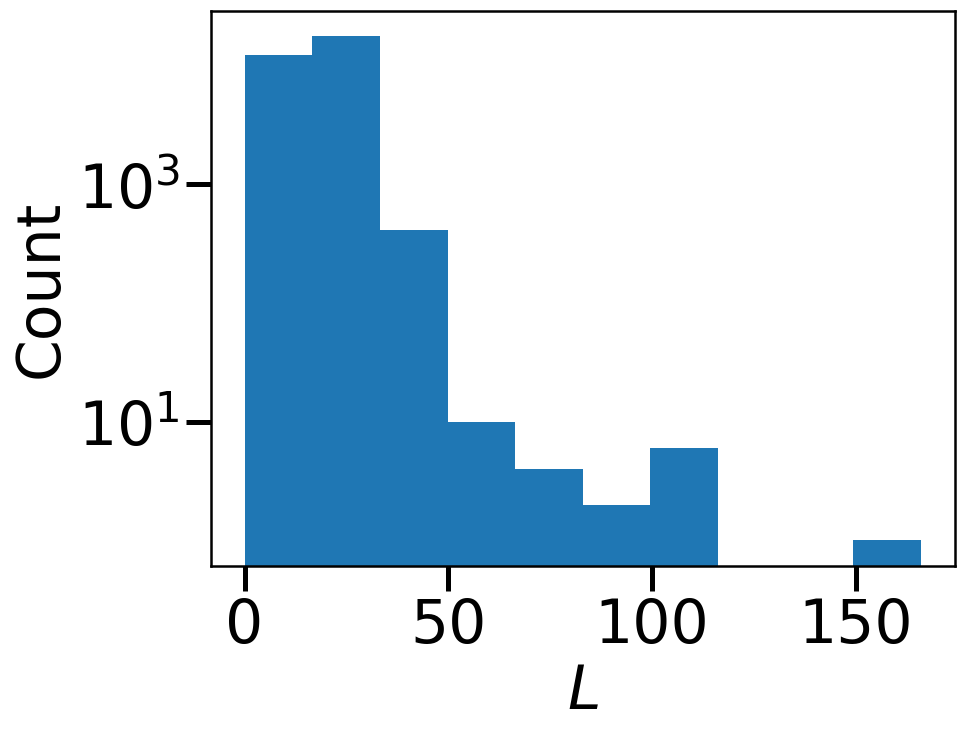

In [23]:
Llist=[]
for k in range(len(TR)):
    if len(TR[k])==len(VR[k]):
        Llist.append(compute_L_first_last_A(TR[k][Frame[k]:].upper(), VR[k][Frame[k]:].upper()))

Llist=np.array(Llist)
Llist=Llist[Llist!=None]
plt.hist(Llist)
plt.xlabel(r'$L$')
plt.ylabel('Count')
plt.semilogy()
#plt.savefig('Count_L.svg')
#plt.savefig('Count_L.png')